# M5 Demand Forecasting - Notebook 2: Segmentation and Baselines

**Goal:** know how hard each part of the assortment is to forecast, and set the accuracy bar that the week 3 machine learning model must beat.

Run `python -m src.run_week2` (add `--with-stats` for ETS and SARIMA) before this notebook. It writes the tables in `reports/tables/` that are read here.

**Sections:** 1) Segmentation (ABC-XYZ and demand pattern), 2) Overall baseline comparison, 3) Accuracy by segment, 4) ETS on a sample, 5) Aggregate level, 6) Example forecasts, 7) Key findings

**How to read the metrics** (lower is better for all):
- **WAPE**: total absolute error divided by total actual sales. Easy to explain to a manager.
- **Bias**: positive means over-forecasting, negative means under-forecasting.
- **RMSSE**: error scaled by how noisy the series is. Below 1.0 beats a one-step naive forecast.
- **wRMSSE**: RMSSE weighted by revenue (bottom level only, so not identical to the official M5 score).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
config.FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

need = ["series_segments.csv", "baseline_metrics.csv", "aggregate_metrics.csv"]
missing = [f for f in need if not (config.TABLES_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing} in {config.TABLES_DIR}.\n"
                            "Run first in a terminal: python -m src.run_week2")

seg = pd.read_csv(config.TABLES_DIR / "series_segments.csv")
metrics = pd.read_csv(config.TABLES_DIR / "baseline_metrics.csv")
agg = pd.read_csv(config.TABLES_DIR / "aggregate_metrics.csv")
agg_fc_path = config.TABLES_DIR / "aggregate_forecasts.csv"
agg_fc = pd.read_csv(agg_fc_path, parse_dates=["date"]) if agg_fc_path.exists() else None
print(f"{len(seg):,} series | {metrics['origin'].nunique()} backtest origins | methods: {sorted(metrics['method'].unique())}")

12,196 series | 3 backtest origins | methods: ['croston_sba', 'ets', 'moving_avg_28d', 'naive', 'seasonal_avg_4w', 'seasonal_naive']


## 1. Segmentation

Not all series are equal. We classify each item-store series using only data **before the first backtest cutoff**, so the segments never see a test window.

- **ABC** by revenue: A = the series making the first 80% of revenue, B = the next 15%, C = the last 5%.
- **XYZ** by variability of weekly demand (coefficient of variation): X below 0.5, Y below 1.0, Z otherwise.
- **Demand pattern** (Syntetos-Boylan-Croston): *smooth*, *erratic*, *intermittent* or *lumpy*, from how often demand occurs and how much its size varies.
- Series with too little history are labelled **NEW**.

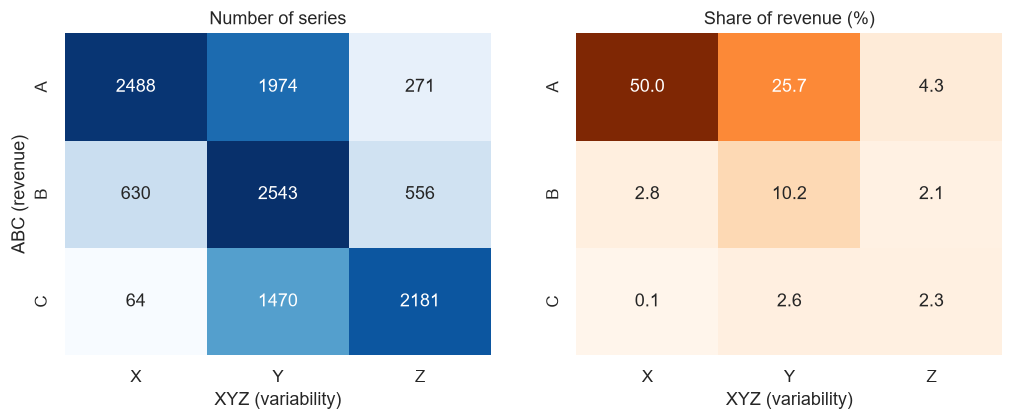

NEW series (too little history): 19


In [2]:
base = seg[seg["abc_xyz"] != "NEW"]
cells_df = (base.groupby(["abc", "xyz"])
            .agg(n_series=("series_id", "count"), revenue=("revenue_window", "sum")).reset_index())
cells_df["pct_revenue"] = 100 * cells_df["revenue"] / cells_df["revenue"].sum()
cnt = cells_df.pivot(index="abc", columns="xyz", values="n_series").reindex(index=list("ABC"), columns=list("XYZ")).fillna(0)
rev = cells_df.pivot(index="abc", columns="xyz", values="pct_revenue").reindex(index=list("ABC"), columns=list("XYZ")).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(cnt, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[0]); axes[0].set(title="Number of series", xlabel="XYZ (variability)", ylabel="ABC (revenue)")
sns.heatmap(rev, annot=True, fmt=".1f", cmap="Oranges", cbar=False, ax=axes[1]); axes[1].set(title="Share of revenue (%)", xlabel="XYZ (variability)", ylabel="")
save(fig, "11_abc_xyz_matrix"); plt.show()
print("NEW series (too little history):", int((seg["abc_xyz"] == "NEW").sum()))

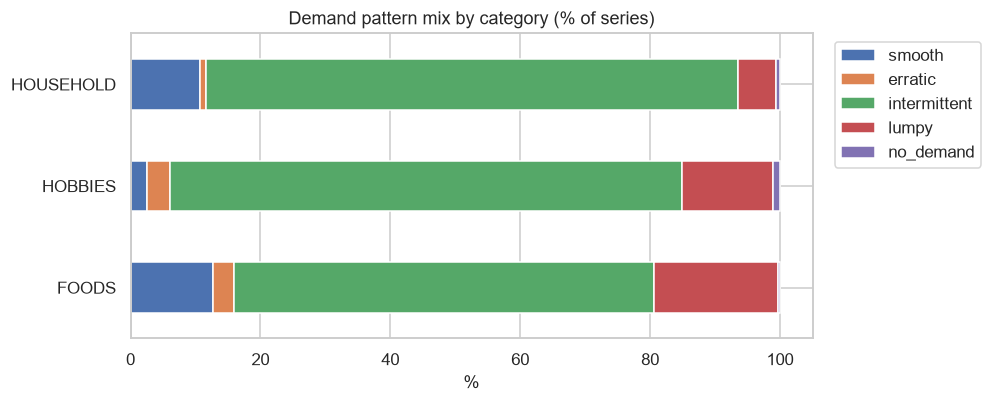

demand_pattern,smooth,erratic,intermittent,lumpy,no_demand
cat_id,,,,,
FOODS,12.7,3.2,64.7,19.1,0.3
HOBBIES,2.5,3.6,78.8,14.1,1.0
HOUSEHOLD,10.7,0.9,82.0,5.8,0.6


In [3]:
mix = pd.crosstab(seg["cat_id"], seg["demand_pattern"], normalize="index") * 100
order = [c for c in ["smooth", "erratic", "intermittent", "lumpy", "no_demand"] if c in mix.columns]
fig, ax = plt.subplots(figsize=(8, 3.6))
mix[order].plot(kind="barh", stacked=True, ax=ax)
ax.set(title="Demand pattern mix by category (% of series)", xlabel="%", ylabel="")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "12_demand_pattern_by_category"); plt.show()
mix[order].round(1)

## 2. Overall baseline comparison

Every method is tested on 3 rolling origins. Each origin forecasts the next 28 days using only earlier data. The bars show the mean over origins, the dots show each origin.

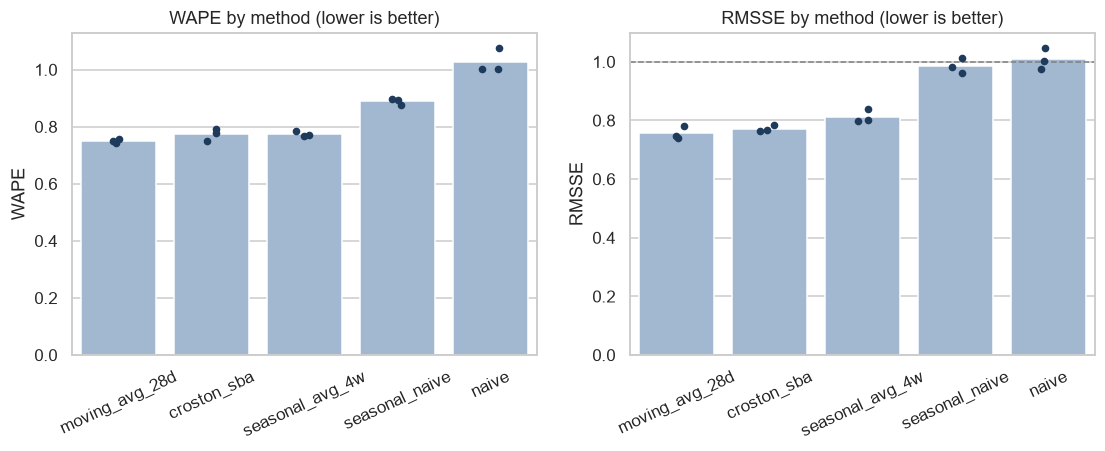

,WAPE,Bias,RMSSE,wRMSSE
method,,,,
moving_avg_28d,0.751,-0.021,0.756,0.864
croston_sba,0.775,-0.021,0.771,0.863
seasonal_avg_4w,0.774,-0.021,0.812,0.908
seasonal_naive,0.888,-0.023,0.986,1.103
naive,1.026,0.247,1.008,1.210


In [4]:
ov = metrics[(metrics["scope"] == "all") & (metrics["level"] == "all")]
tbl = ov.groupby("method")[["WAPE", "Bias", "RMSSE", "wRMSSE"]].mean().sort_values("RMSSE")
order = tbl.index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric in zip(axes, ["WAPE", "RMSSE"]):
    sns.barplot(data=ov, x="method", y=metric, order=order, errorbar=None, color="#9ab7d8", ax=ax)
    sns.stripplot(data=ov, x="method", y=metric, order=order, color="#1f3b5c", size=5, ax=ax)
    ax.set(title=f"{metric} by method (lower is better)", xlabel="")
    ax.tick_params(axis="x", rotation=25)
axes[1].axhline(1.0, color="grey", ls="--", lw=1)
save(fig, "13_baseline_comparison"); plt.show()
tbl.round(3)

## 3. Accuracy by segment

The best method is rarely the same for every segment. This is the key table for week 3: it shows where a better model can add the most value.

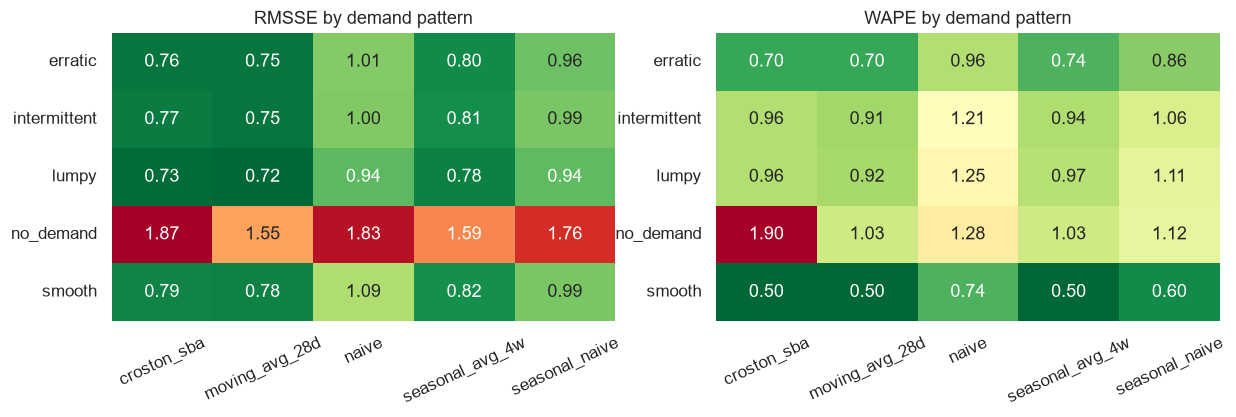

In [5]:
bp = metrics[(metrics["scope"] == "all") & (metrics["level"] == "demand_pattern")]
piv_r = bp.pivot_table(index="group", columns="method", values="RMSSE", aggfunc="mean")
piv_w = bp.pivot_table(index="group", columns="method", values="WAPE", aggfunc="mean")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
sns.heatmap(piv_r, annot=True, fmt=".2f", cmap="RdYlGn_r", cbar=False, ax=axes[0]); axes[0].set(title="RMSSE by demand pattern", xlabel="", ylabel="")
sns.heatmap(piv_w, annot=True, fmt=".2f", cmap="RdYlGn_r", cbar=False, ax=axes[1]); axes[1].set(title="WAPE by demand pattern", xlabel="", ylabel="")
for ax in axes: ax.tick_params(axis="x", rotation=25)
save(fig, "14_accuracy_by_demand_pattern"); plt.show()

In [6]:
def best_method(level, metric="RMSSE"):
    d = metrics[(metrics["scope"] == "all") & (metrics["level"] == level)]
    d = d.groupby(["group", "method"]).agg(value=(metric, "mean"), n_series=("n_series", "mean")).reset_index()
    best = d.loc[d.groupby("group")["value"].idxmin()].set_index("group")
    return best.rename(columns={"value": f"best_{metric}"}).round(3)

print("Best method per ABC-XYZ cell (by RMSSE):")
display(best_method("abc_xyz"))
print("Best method per demand pattern (by RMSSE):")
display(best_method("demand_pattern"))

Best method per ABC-XYZ cell (by RMSSE):


,method,best_RMSSE,n_series
group,,,
AX,moving_avg_28d,0.766,2488.000
AY,moving_avg_28d,0.789,1974.000
AZ,moving_avg_28d,0.884,271.000
BX,croston_sba,0.712,630.000
BY,moving_avg_28d,0.734,2543.000
BZ,moving_avg_28d,0.794,556.000
CX,croston_sba,0.719,64.000
CY,moving_avg_28d,0.707,1470.000
CZ,moving_avg_28d,0.762,2181.000


Best method per demand pattern (by RMSSE):


,method,best_RMSSE,n_series
group,,,
erratic,moving_avg_28d,0.754,304.000
intermittent,moving_avg_28d,0.752,8929.667
lumpy,moving_avg_28d,0.721,1656.333
no_demand,moving_avg_28d,1.547,67.000
smooth,moving_avg_28d,0.784,1233.333


## 4. ETS on a sample of series

ETS is fitted one series at a time, so it runs on a stratified sample (`--with-stats`). To compare fairly, the baselines below are scored on **the same sample**.

In [7]:
if "ets_sample" in metrics["scope"].values:
    s = metrics[(metrics["scope"] == "ets_sample") & (metrics["level"] == "all")]
    t = s.groupby("method").agg(WAPE=("WAPE", "mean"), Bias=("Bias", "mean"), RMSSE=("RMSSE", "mean"),
                                n_series=("n_series", "mean"), n_fallback=("n_fallback", "mean")).sort_values("RMSSE")
    display(t.round(3))
    print("n_fallback = series where ETS failed and the seasonal average was used instead.")
else:
    print("No ETS results yet. Run: python -m src.run_week2 --with-stats")

,WAPE,Bias,RMSSE,n_series,n_fallback
method,,,,,
ets,0.791,0.015,0.736,302.0,0.0
moving_avg_28d,0.809,0.015,0.742,302.0,0.0
croston_sba,0.830,0.014,0.759,302.0,0.0
seasonal_avg_4w,0.841,0.015,0.799,302.0,0.0
seasonal_naive,0.967,0.015,0.982,302.0,0.0
naive,1.112,0.298,0.989,302.0,0.0


n_fallback = series where ETS failed and the seasonal average was used instead.


## 5. Aggregate level (store x category and total)

At the item level, demand is noisy. When we add items up, noise cancels and the weekly pattern dominates, so classical models such as ETS and SARIMA become competitive. This matters for planning at warehouse or category level.

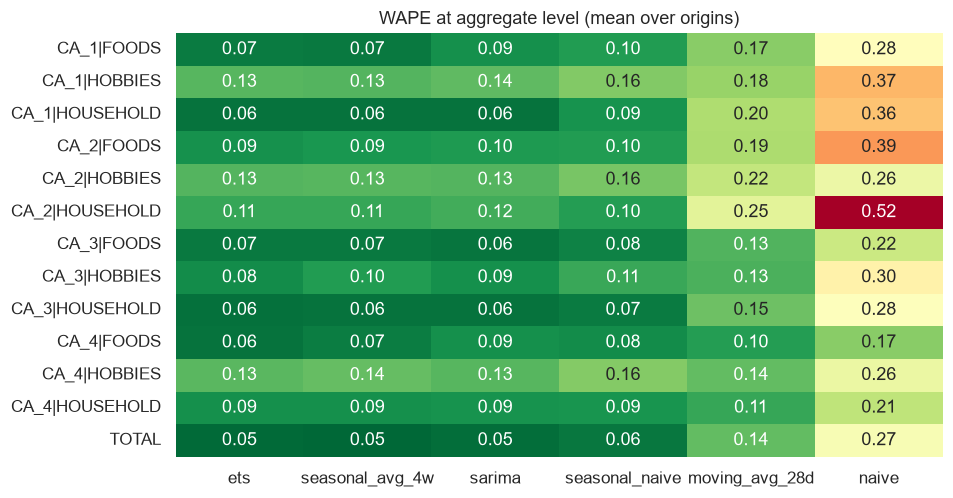

In [8]:
t = agg.groupby(["group", "method"])["WAPE"].mean().unstack("method")
t = t[t.mean().sort_values().index]
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(t, annot=True, fmt=".2f", cmap="RdYlGn_r", cbar=False, ax=ax)
ax.set(title="WAPE at aggregate level (mean over origins)", xlabel="", ylabel="")
save(fig, "15_aggregate_wape"); plt.show()

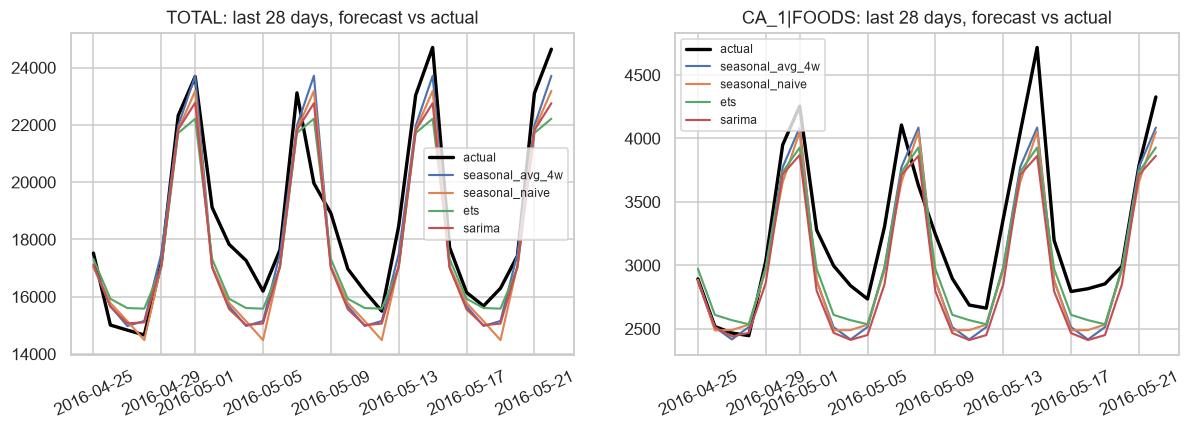

In [9]:
if agg_fc is not None:
    last = agg_fc[agg_fc["origin"] == agg_fc["origin"].max()]
    groups = ["TOTAL"] + [g for g in last["group"].unique() if g != "TOTAL"][:1]
    fig, axes = plt.subplots(1, len(groups), figsize=(6.5 * len(groups), 3.8), squeeze=False)
    for ax, g in zip(axes[0], groups):
        d = last[last["group"] == g]
        act = d[d["method"] == d["method"].iloc[0]]
        ax.plot(act["date"], act["actual"], color="black", lw=2.2, label="actual")
        for m in [x for x in ["seasonal_avg_4w", "seasonal_naive", "ets", "sarima"] if x in d["method"].unique()]:
            dd = d[d["method"] == m]
            ax.plot(dd["date"], dd["forecast"], lw=1.4, label=m)
        ax.set(title=f"{g}: last 28 days, forecast vs actual"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=25)
    save(fig, "16_aggregate_forecast_vs_actual"); plt.show()

## 6. Example forecasts for one series of each demand pattern

The most valuable series of each pattern, last 28 days (the last backtest window).

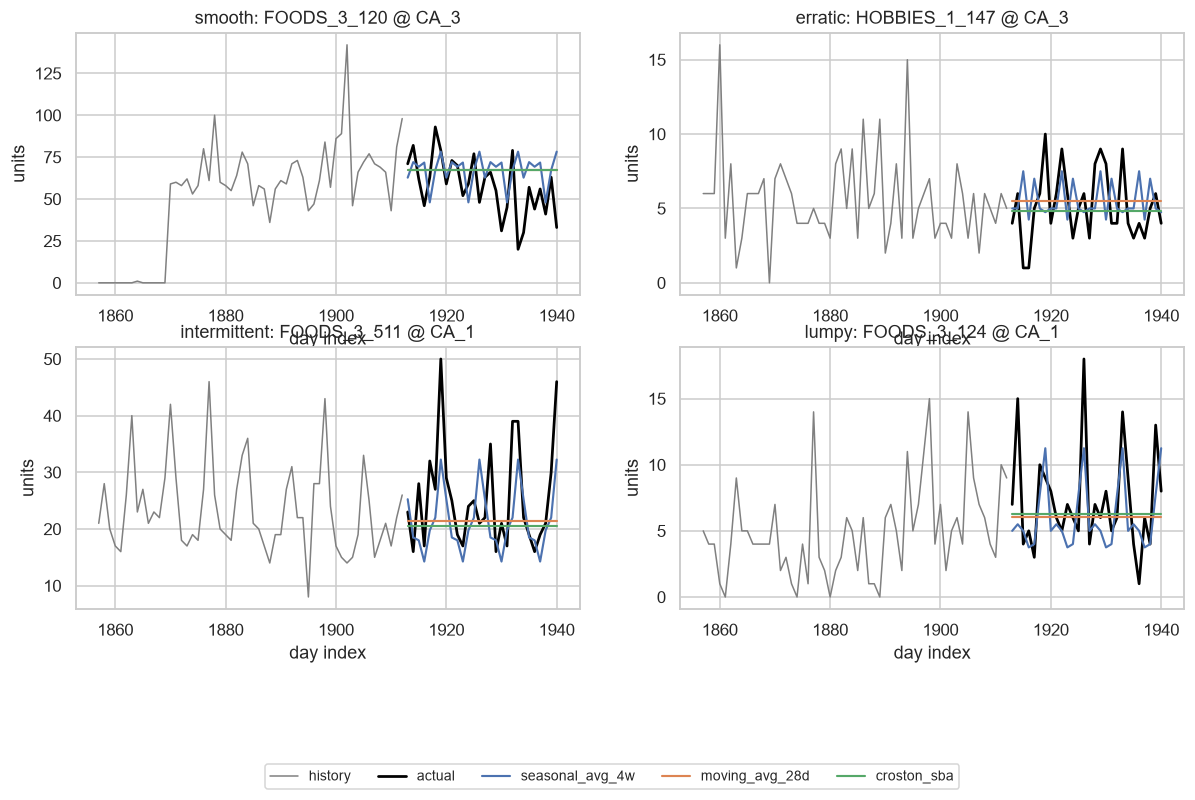

In [10]:
from src.data_access import load_sales_data, masked_float
from src.baselines import BASELINES

data = load_sales_data(verbose=False)
Yf = masked_float(data)
H = config.HORIZON
c = data.n_days - H
fc = {m: BASELINES[m](Yf, c, H) for m in ["seasonal_avg_4w", "moving_avg_28d", "croston_sba"]}

patterns = [p for p in ["smooth", "erratic", "intermittent", "lumpy"] if (seg["demand_pattern"] == p).any()]
n_rows = max(1, int(np.ceil(len(patterns) / 2)))
fig, axes = plt.subplots(n_rows, 2, figsize=(13, 3.4 * n_rows), squeeze=False)
for ax, p in zip(axes.ravel(), patterns):
    cand = seg[(seg["demand_pattern"] == p) & (seg["abc_xyz"] != "NEW")].sort_values("revenue_window", ascending=False)
    if cand.empty:
        continue
    i = cand.index[0]
    hist_x = np.arange(c - 56, c); fut_x = np.arange(c, c + H)
    ax.plot(hist_x, data.Y[i, c - 56:c], color="grey", lw=1, label="history")
    ax.plot(fut_x, data.Y[i, c:c + H], color="black", lw=1.8, label="actual")
    for m, F in fc.items():
        ax.plot(fut_x, F[i], lw=1.4, label=m)
    ax.set(title=f"{p}: {seg.loc[i, 'item_id']} @ {seg.loc[i, 'store_id']}", xlabel="day index", ylabel="units")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=9, bbox_to_anchor=(0.5, -0.14))
for ax in axes.ravel()[len(patterns):]:
    ax.axis("off")
save(fig, "17_example_forecasts"); plt.show()

## 7. Key findings (fill in after running on the real M5 data)

Write 5-8 bullets with numbers from your own tables:

- **Segments:** what share of series is A, and what share of revenue do they make? How much of the assortment is intermittent or lumpy?
- **Best simple method:** which baseline wins overall (WAPE and RMSSE)? Is the difference large?
- **Segment effect:** which method wins for smooth vs intermittent series? Does Croston-SBA help where it should?
- **Bias:** does any method systematically over- or under-forecast? What would that mean for stock?
- **ETS vs baselines:** does ETS beat the seasonal average on the sample? Was the extra complexity worth it?
- **Aggregate level:** how much more accurate are forecasts at store x category and total level than at item level?
- **Target for week 3:** state the number the LightGBM model has to beat (for example, the best baseline's WAPE and RMSSE on the last origin), and where you expect the biggest gain.

*(Replace this cell with your own findings.)*